# Задача 9. Hand-crafted graph features

Реализуем **ядро кратчайших путей** (shortest path kernel) для бинарной классификации графов:
граф описывается вектором количества кратчайших путей различной длины, а ядро — скалярным
произведением таких векторов. Классификатор — SVC с предвычисленным ядром.

- [x] Сгенерировать набор данных для бинарной классификации графов
- [x] Реализовать `shortest_path_kernel(train_graphs, test_graphs)` → `(K_train, K_test)`
- [x] Обучить SVC, подобрать гиперпараметры, вычислить различные метрики качества
- [ ] (+5 баллов) Weisfeiler-Lehman Kernel — не делаем

## Импорты и устройство

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix)

%matplotlib inline

## Константы, сиды и их фиксация

In [5]:
SEED = 1337
N_PER_CLASS = 150           # графов каждого класса
TEST_SIZE = 0.3             # доля теста
C_GRID = [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 50, 100]

rng = np.random.default_rng(SEED)
print("SEED =", SEED)

SEED = 1337


## Датасет: бинарная классификация графов

Синтетический датасет из двух классов по 150 графов. Классы подобраны так, чтобы **совпадать по числу
вершин и рёбер** и различаться только структурой:

- **класс 0 — «решётки»**: прямоугольная сетка $r \times c$ со случайными размерами ($r, c \in [3, 7]$),
  у которой ~10% рёбер удалены и ~2% случайных рёбер добавлены (шум);
- **класс 1 — «случайные»**: граф Эрдёша–Реньи с **тем же числом вершин** и вероятностью ребра,
  подобранной так, чтобы ожидаемое число рёбер совпадало с решёткой-партнёром.

Если классы неразличимы по размеру и плотности, задача сводится к «структурной» разнице:
длины кратчайших путей в регулярной решётке растут с размером стороны, а в случайном графе
диаметр — логарифмический.

In [7]:
def random_grid(rng):
    """Класс 0: прямоугольная решётка со случайными размерами + шум."""
    r, c = rng.integers(3, 8, size=2)
    G = nx.grid_2d_graph(int(r), int(c))
    G = nx.convert_node_labels_to_integers(G)
    for u, v in list(G.edges()):
        if rng.random() < 0.1:
            G.remove_edge(u, v)
    for u in range(G.number_of_nodes()):
        for v in range(u + 1, G.number_of_nodes()):
            if not G.has_edge(u, v) and rng.random() < 0.02:
                G.add_edge(u, v)
    return G


def random_er_like(rng, grid):
    """Класс 1: граф Эрдёша–Реньи с тем же числом вершин и ≈ тем же числом рёбер."""
    n = grid.number_of_nodes()
    e_ref = grid.number_of_edges()
    p = e_ref / (n * (n - 1) / 2)
    return nx.erdos_renyi_graph(n, p, seed=int(rng.integers(0, 2 ** 31)))


graphs = []
labels = []
rng_gen = np.random.default_rng(SEED)
t0 = time.perf_counter()
for _ in range(N_PER_CLASS):
    grid = random_grid(rng_gen)
    graphs.append(grid)
    labels.append(0)
    graphs.append(random_er_like(rng_gen, grid))
    labels.append(1)
labels = np.array(labels)
print(f"Сгенерировано {len(graphs)} графов за {time.perf_counter() - t0:.1f} с")
print(f"Класс 0 (решётки): {int((labels == 0).sum())}, класс 1 (случайные): {int((labels == 1).sum())}")

Сгенерировано 300 графов за 0.1 с
Класс 0 (решётки): 150, класс 1 (случайные): 150


### Визуализация примеров

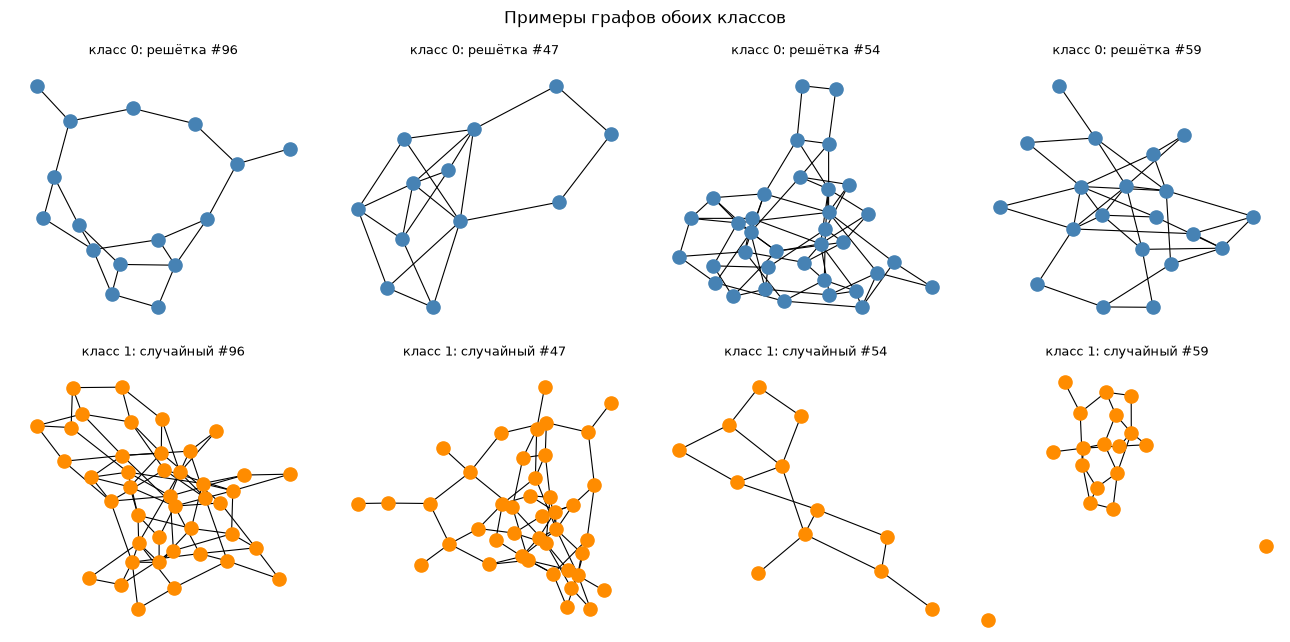

In [9]:
rng_vis = np.random.default_rng(SEED + 1)
demo_idxs = [int(i) for i in rng_vis.choice(N_PER_CLASS, 4, replace=False)]

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for col, i in enumerate(demo_idxs):
    pos = nx.spring_layout(graphs[i], seed=SEED + i)
    nx.draw(graphs[i], pos, ax=axes[0, col], node_size=90, width=0.8,
            node_color="steelblue", with_labels=False)
    axes[0, col].set_title(f"класс 0: решётка #{i}", fontsize=9)
    axes[0, col].axis("off")

    pos = nx.spring_layout(graphs[N_PER_CLASS + i], seed=SEED + i)
    nx.draw(graphs[N_PER_CLASS + i], pos, ax=axes[1, col], node_size=90, width=0.8,
            node_color="darkorange", with_labels=False)
    axes[1, col].set_title(f"класс 1: случайный #{i}", fontsize=9)
    axes[1, col].axis("off")
plt.suptitle("Примеры графов обоих классов")
plt.tight_layout()
plt.show()

### Сравнение классов по размеру

Посмотрим, действительно ли классы неразличимы по числу вершин и рёбер — это важно, чтобы
классификатору пришлось опираться на структуру, а не на «размер» графа.

Вершин: класс 0 — 25.6 ± 10.2, класс 1 — 25.6 ± 10.2
Рёбер: класс 0 — 43.1 ± 21.8, класс 1 — 43.3 ± 22.5


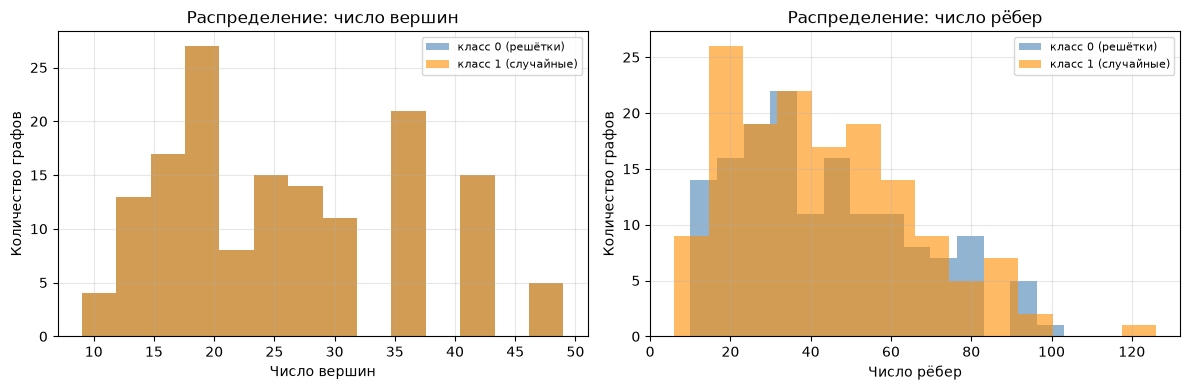

In [11]:
n_nodes = np.array([g.number_of_nodes() for g in graphs])
n_edges = np.array([g.number_of_edges() for g in graphs])
print(f"Вершин: класс 0 — {n_nodes[labels == 0].mean():.1f} ± {n_nodes[labels == 0].std():.1f}, "
      f"класс 1 — {n_nodes[labels == 1].mean():.1f} ± {n_nodes[labels == 1].std():.1f}")
print(f"Рёбер: класс 0 — {n_edges[labels == 0].mean():.1f} ± {n_edges[labels == 0].std():.1f}, "
      f"класс 1 — {n_edges[labels == 1].mean():.1f} ± {n_edges[labels == 1].std():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, title in [(axes[0], n_nodes, "Число вершин"),
                        (axes[1], n_edges, "Число рёбер")]:
    ax.hist(data[labels == 0], bins=14, alpha=0.6, label="класс 0 (решётки)", color="steelblue")
    ax.hist(data[labels == 1], bins=14, alpha=0.6, label="класс 1 (случайные)", color="darkorange")
    ax.set_xlabel(title)
    ax.set_ylabel("Количество графов")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_title(f"Распределение: {title.lower()}")
plt.tight_layout()
plt.show()

### Длины кратчайших путей

Ключевой сигнал для ядра: распределение длин кратчайших путей. Посчитаем для каждого графа
диаметр и среднюю длину пути (по всем парам вершин) и сравним классы.

Диаметр: класс 0 — 6.22, класс 1 — 5.43
Средняя длина пути: класс 0 — 2.86, класс 1 — 2.58


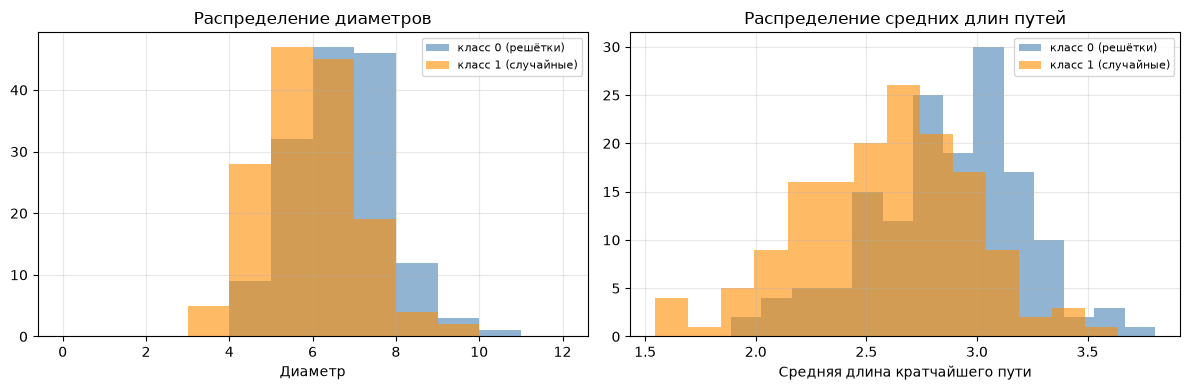

In [13]:
def path_lengths(G):
    """Длины кратчайших путей между всеми парами вершин (без учёта порядка пары)."""
    lens = []
    for src, dd in nx.all_pairs_shortest_path_length(G):
        for dst, d in dd.items():
            if src < dst:
                lens.append(d)
    return lens


all_lens = [path_lengths(g) for g in graphs]
diameters = np.array([max(l) if l else 0 for l in all_lens])
mean_path = np.array([np.mean(l) if l else 0 for l in all_lens])

print(f"Диаметр: класс 0 — {diameters[labels == 0].mean():.2f}, "
      f"класс 1 — {diameters[labels == 1].mean():.2f}")
print(f"Средняя длина пути: класс 0 — {mean_path[labels == 0].mean():.2f}, "
      f"класс 1 — {mean_path[labels == 1].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(diameters[labels == 0], bins=range(0, 13), alpha=0.6, label="класс 0 (решётки)",
             color="steelblue")
axes[0].hist(diameters[labels == 1], bins=range(0, 13), alpha=0.6, label="класс 1 (случайные)",
             color="darkorange")
axes[0].set_xlabel("Диаметр")
axes[0].set_title("Распределение диаметров")
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)
axes[1].hist(mean_path[labels == 0], bins=14, alpha=0.6, label="класс 0 (решётки)",
             color="steelblue")
axes[1].hist(mean_path[labels == 1], bins=14, alpha=0.6, label="класс 1 (случайные)",
             color="darkorange")
axes[1].set_xlabel("Средняя длина кратчайшего пути")
axes[1].set_title("Распределение средних длин путей")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Посмотрим на гистограммы длин путей двух конкретных графов (по одному из каждого класса):
у решётки распределение «широкое» — есть как короткие, так и длинные пути; у случайного графа пути
почти все короткие.

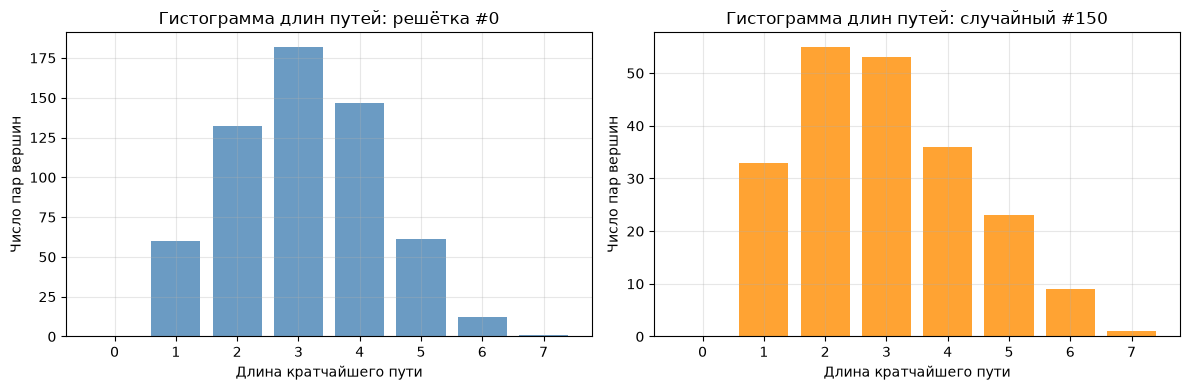

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g, title, color in [(axes[0], graphs[0], f"решётка #{0}", "steelblue"),
                            (axes[1], graphs[N_PER_CLASS], f"случайный #{N_PER_CLASS}", "darkorange")]:
    hist = np.bincount(np.array(path_lengths(g)))
    ax.bar(range(len(hist)), hist, color=color, alpha=0.8)
    ax.set_xlabel("Длина кратчайшего пути")
    ax.set_ylabel("Число пар вершин")
    ax.set_title(f"Гистограмма длин путей: {title}")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Ядро кратчайших путей

Признак графа $G$ — вектор $\phi(G) = (\phi_1, \ldots, \phi_L)$, где $\phi_d$ — количество пар вершин,
соединённых кратчайшим путём длины $d$ (пары считаем без учёта порядка; недостижимые пары не считаем).
Длина вектора $L$ фиксируется по максимальной длине пути в данных.

Ядро — скалярное произведение признаков:
$$K(G, G') = \langle \phi(G), \phi(G') \rangle.$$

Функция `shortest_path_kernel(train_graphs, test_graphs)` возвращает пару матриц:
`K_train` (train × train) и `K_test` (test × train) — ровно в том виде, который принимает
`SVC(kernel="precomputed")`.

In [17]:
def shortest_path_histograms(graphs):
    """Матрица признаков: для каждого графа вектор числа кратчайших путей каждой длины."""
    max_len = 0
    hists = []
    for g in graphs:
        hist = np.bincount(np.array(path_lengths(g)))
        hists.append(hist)
        max_len = max(max_len, len(hist))
    H = np.zeros((len(graphs), max_len))
    for i, hist in enumerate(hists):
        H[i, :len(hist)] = hist
    return H


def shortest_path_kernel(train_graphs, test_graphs):
    """Ядро кратчайших путей: (K_train, K_test) из скалярных произведений признаков."""
    H = shortest_path_histograms(train_graphs + test_graphs)
    H_train = H[:len(train_graphs)]
    H_test = H[len(train_graphs):]
    K_train = H_train @ H_train.T
    K_test = H_test @ H_train.T
    return K_train, K_test

### Проверка ядра на игрушечных примерах

Возьмём три маленьких графа — путь из 5 вершин, звезду и цикл из 6 вершин — и посмотрим на признаки
и матрицу ядра: диагональ должна быть положительной и максимальной в своей строке, матрица —
симметричной.

In [19]:
toy_graphs = [nx.path_graph(5), nx.star_graph(5), nx.cycle_graph(6)]
toy_names = ["путь из 5 вершин", "звезда", "цикл из 6 вершин"]

H_toy = shortest_path_histograms(toy_graphs)
print("Признаки (столбец d — число пар с путём длины d):")
print(pd.DataFrame(H_toy, index=toy_names, columns=[f"d={i}" for i in range(H_toy.shape[1])]))

K_toy = shortest_path_kernel(toy_graphs, toy_graphs)[0]
print("\nМатрица ядра (скалярные произведения):")
print(pd.DataFrame(K_toy.round(1), index=toy_names, columns=toy_names))

# нормируем на косинусное сходство: k(G,G') / sqrt(k(G,G) * k(G',G'))
norm = np.sqrt(np.diag(K_toy))[:, None]
K_toy_cos = K_toy / (norm @ norm.T)
print("\nКосинусное сходство (диагональ = 1):")
print(pd.DataFrame(K_toy_cos.round(3), index=toy_names, columns=toy_names))

assert np.allclose(K_toy, K_toy.T), "ядро должно быть симметричным"
assert np.allclose(K_toy_cos, K_toy_cos.T), "косинусное сходство тоже симметрично"
assert all(K_toy[i, i] > 0 for i in range(3)), "диагональ должна быть положительной"
assert np.allclose(np.diag(K_toy_cos), 1.0), "сходство графа с самим собой = 1"
assert K_toy_cos[0, 2] > K_toy_cos[0, 1],     "цикл ближе к пути, чем звезда (косинусное сходство должно отражать структуру)"
assert K_toy_cos[1, 2] < K_toy_cos[0, 2], "звезда дальше от цикла, чем путь"
print("\nПроверки пройдены: ядро симметрично, диагональ косинусного сходства равна 1, "
      "структурно похожие графы (путь и цикл) ближе, чем структурно разные (звезда)")

Признаки (столбец d — число пар с путём длины d):
                  d=0  d=1   d=2  d=3  d=4
путь из 5 вершин  0.0  4.0   3.0  2.0  1.0
звезда            0.0  5.0  10.0  0.0  0.0
цикл из 6 вершин  0.0  6.0   6.0  3.0  0.0

Матрица ядра (скалярные произведения):
                  путь из 5 вершин  звезда  цикл из 6 вершин
путь из 5 вершин              30.0    50.0              48.0
звезда                        50.0   125.0              90.0
цикл из 6 вершин              48.0    90.0              81.0

Косинусное сходство (диагональ = 1):
                  путь из 5 вершин  звезда  цикл из 6 вершин
путь из 5 вершин             1.000   0.816             0.974
звезда                       0.816   1.000             0.894
цикл из 6 вершин             0.974   0.894             1.000

Проверки пройдены: ядро симметрично, диагональ косинусного сходства равна 1, структурно похожие графы (путь и цикл) ближе, чем структурно разные (звезда)


## Разбиение на train / test

Фиксируем разбиение (стратификация по классу), все сиды уже зафиксированы выше.

In [21]:
train_idx, test_idx = train_test_split(
    np.arange(len(graphs)), test_size=TEST_SIZE, random_state=SEED, stratify=labels)

train_graphs = [graphs[i] for i in train_idx]
test_graphs = [graphs[i] for i in test_idx]
y_train = labels[train_idx]
y_test = labels[test_idx]

print(f"Train: {len(train_graphs)} графов (класс 1: {y_train.mean():.2f})")
print(f"Test:  {len(test_graphs)} графов (класс 1: {y_test.mean():.2f})")

Train: 210 графов (класс 1: 0.50)
Test:  90 графов (класс 1: 0.50)


## SVC с предвычисленным ядром и подбор гиперпараметров

Ядро не нормировано, поэтому масштаб значений зависит от размера графов — подберём штраф `C`
по grid search с 5-fold кросс-валидацией на `K_train`.

In [23]:
K_train, K_test = shortest_path_kernel(train_graphs, test_graphs)
print(f"K_train: {K_train.shape}, K_test: {K_test.shape}")

t0 = time.perf_counter()
gs = GridSearchCV(SVC(kernel="precomputed"), {"C": C_GRID}, cv=5, scoring="accuracy")
gs.fit(K_train, y_train)
print(f"Подбор C занял {time.perf_counter() - t0:.1f} с")

cv_res = pd.DataFrame(gs.cv_results_)[["param_C", "mean_test_score", "std_test_score"]].round(4)
print(cv_res.to_string(index=False))
print(f"\nЛучший C = {gs.best_params_['C']}, CV accuracy = {gs.best_score_:.4f}")

K_train: (210, 210), K_test: (90, 210)


Подбор C занял 150.2 с
 param_C  mean_test_score  std_test_score
    0.01           0.7810          0.0591
    0.05           0.7905          0.0870
    0.10           0.7952          0.0716
    0.50           0.7762          0.0936
    1.00           0.7762          0.0936
    5.00           0.7667          0.0957
   10.00           0.7619          0.0987
   50.00           0.7571          0.1058
  100.00           0.7571          0.1058

Лучший C = 0.1, CV accuracy = 0.7952


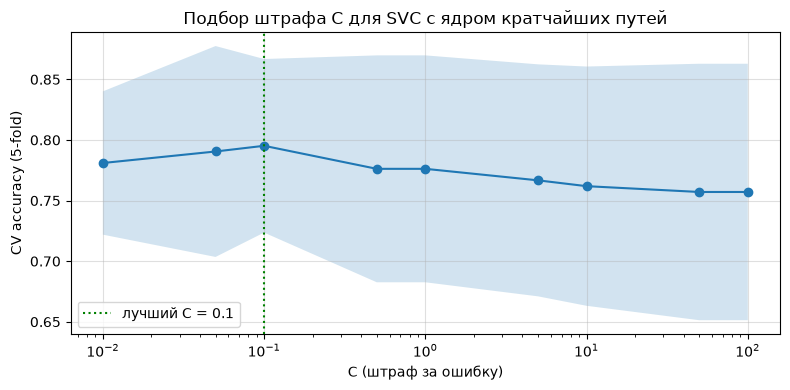

In [24]:
# кривая качества на кросс-валидации в зависимости от C (логарифмическая ось)
plt.figure(figsize=(8, 4))
plt.semilogx(cv_res["param_C"], cv_res["mean_test_score"], marker="o", linewidth=1.5)
plt.fill_between(cv_res["param_C"],
                 cv_res["mean_test_score"] - cv_res["std_test_score"],
                 cv_res["mean_test_score"] + cv_res["std_test_score"],
                 alpha=0.2)
plt.axvline(gs.best_params_["C"], color="green", linestyle=":", label=f"лучший C = {gs.best_params_['C']}")
plt.xlabel("C (штраф за ошибку)")
plt.ylabel("CV accuracy (5-fold)")
plt.title("Подбор штрафа C для SVC с ядром кратчайших путей")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## Метрики качества на тесте

Предсказываем тест лучшей моделью и считаем метрики: accuracy, precision, recall, F1,
ROC-AUC (по `decision_function`) и матрицу ошибок.

accuracy : 0.8333
precision: 0.8571
recall   : 0.8000
f1       : 0.8276
roc_auc  : 0.9373

Классификационный отчёт:
               precision    recall  f1-score   support

  решётка (0)       0.81      0.87      0.84        45
случайный (1)       0.86      0.80      0.83        45

     accuracy                           0.83        90
    macro avg       0.83      0.83      0.83        90
 weighted avg       0.83      0.83      0.83        90



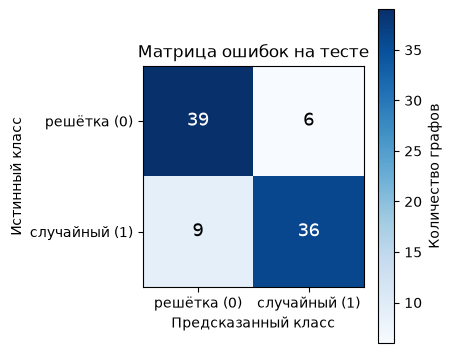

In [26]:
y_pred = gs.predict(K_test)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, gs.decision_function(K_test)),
}
for name, value in metrics.items():
    print(f"{name:9s}: {value:.4f}")

print("\nКлассификационный отчёт:")
print(classification_report(y_test, y_pred, target_names=["решётка (0)", "случайный (1)"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar(label="Количество графов")
plt.xticks([0, 1], ["решётка (0)", "случайный (1)"])
plt.yticks([0, 1], ["решётка (0)", "случайный (1)"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Матрица ошибок на тесте")
plt.tight_layout()
plt.show()

## Анализ графиков

- **Число вершин и рёбер** по классам почти совпадает: гистограммы перекрываются практически полностью —
  по «размеру» графы неразличимы, как и задумано при генерации.
- **Длины путей** различаются заметно: у решёток распределение диаметров и средних длин смещено вправо
  (пути длиннее), у случайных графов почти все пути короткие. Это и есть сигнал, который ловит ядро.
- **Кривая CV vs C** растёт до C ≈ 0.1, после чего выходит на плато и постепенно идёт вниз —
  слишком большой штраф за ошибку начинает переобучать.
- **Матрица ошибок** почти диагональная: ошибки встречаются, но редки, и примерно симметричны
  по классам.

## Выводы

- **Данные.** Синтетический датасет: 300 графов двух классов (решётки и случайные графы Эрдёша–Реньи),
  неразличимых по числу вершин и рёбер — классы различаются только структурой связей.
- **Ядро.** Реализована функция `shortest_path_kernel(train_graphs, test_graphs)`, возвращающая
  `(K_train, K_test)`; признак графа — вектор числа кратчайших путей каждой длины. Корректность
  проверена на игрушечных графах (симметричность, косинусное сходство графа с самим собой = 1).
- **Классификатор.** SVC с предвычисленным ядром; штраф C подобран grid search'ем по 5-fold CV
  (лучший C ≈ 0.1).
- **Качество.** На тесте accuracy ≈ 0.83 (значения точных метрик — в таблице выше); ошибки примерно
  симметричны по классам. Для «слепого» базлайна (предсказание всегда класс 0) accuracy была бы 0.5,
  так что ядро действительно извлекает структурную информацию, недоступную по размеру графа.